<a href="https://colab.research.google.com/github/unento/audio-diffusion-synth/blob/main/path_c_linear_diffusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Path C: class-conditional linear-frequency spectrogram diffusion

Same model, data, and training recipe as Path A. The only change is the frequency axis:
the STFT is pooled into 64 bands of equal width in Hz instead of 64 mel-spaced bands.
Comparing A and C therefore tests one thing: whether the mel warping helps or hurts.

Requires the updated `common.py` (with `LinearFrontEnd`) and the `frontend.json` created by
the Path A notebook. Set `QUICK_TEST = True` first to run the whole notebook in a few minutes.

## 1. Setup

In [ ]:
!pip install -q diffusers accelerate soundfile

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import sys

import matplotlib.pyplot as plt
import torch

THESIS_DIR = "/content/drive/MyDrive/thesis"   # folder that holds common.py
sys.path.append(THESIS_DIR)
import common as C

assert hasattr(C, "LinearFrontEnd"), "common.py on Drive is the old version: upload the updated file, then restart the session"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


## 2. Config

Keep `total_steps` equal to Path A's so the two paths get the same training budget.

In [ ]:
QUICK_TEST = False          # True: short run to check the notebook end to end

cfg = C.Config(total_steps=300, inference_steps=20) if QUICK_TEST else C.Config(total_steps=5000)
C.seed_everything(cfg.seed)

# Path C settings (identical to Path A's)
DROPOUT     = 0.1
GUIDANCE    = 1.0           # keep at 1.0 for distribution metrics
N_PER_CLASS = 2 if QUICK_TEST else 16

RUN_DIR         = f"{cfg.out_root}/path_c_quick" if QUICK_TEST else f"{cfg.out_root}/path_c"
MEL_FRONTEND    = f"{cfg.out_root}/frontend.json"            # shared; created by the Path A notebook
LINEAR_FRONTEND = f"{cfg.out_root}/frontend_linear.json"     # created here
LINEAR_FILE     = f"{cfg.out_root}/samples/path_c_linear.pt" # generated samples in Path C's own space
MEL_FILE        = f"{cfg.out_root}/samples/path_c.pt"        # the same samples converted to mel
SAMPLE_SHAPE    = (1, cfg.n_mels, cfg.spec_frames)

band_hz = cfg.sample_rate / 2 / (cfg.n_mels + 1)
print(f"{cfg.n_mels} linear bands, centres {band_hz:.0f} Hz apart, from 0 to {cfg.sample_rate // 2} Hz")

64 linear bands, centres 123 Hz apart, from 0 to 8000 Hz


## 3. Data and front ends

Same split and crops as Paths A and B. The linear front end gets its own dB window,
calibrated on the training split, because equal-width bands carry different levels from
mel bands. The mel front end is loaded only to convert samples for evaluation.

In [ ]:
data = C.load_esc50(cfg)
train_split, heldout_split = C.split_by_fold(data, cfg)
train_set = C.CropDataset(train_split, cfg)
print(f"train clips: {len(train_split['waveforms'])} | held-out clips: {len(heldout_split['waveforms'])}")

assert os.path.exists(MEL_FRONTEND), "run the Path A notebook first: it creates the shared mel front end"
mel_frontend = C.MelFrontEnd.load(MEL_FRONTEND, cfg, device=device)

if os.path.exists(LINEAR_FRONTEND):
    frontend = C.LinearFrontEnd.load(LINEAR_FRONTEND, cfg, device=device)
else:
    frontend = C.LinearFrontEnd(cfg, device=device).fit(train_split["waveforms"])
    frontend.save(LINEAR_FRONTEND)
print(f"linear dB window: [{frontend.db_max - cfg.db_range:.1f}, {frontend.db_max:.1f}]")

train clips: 1600 | held-out clips: 400
linear dB window: [-41.3, 38.7]


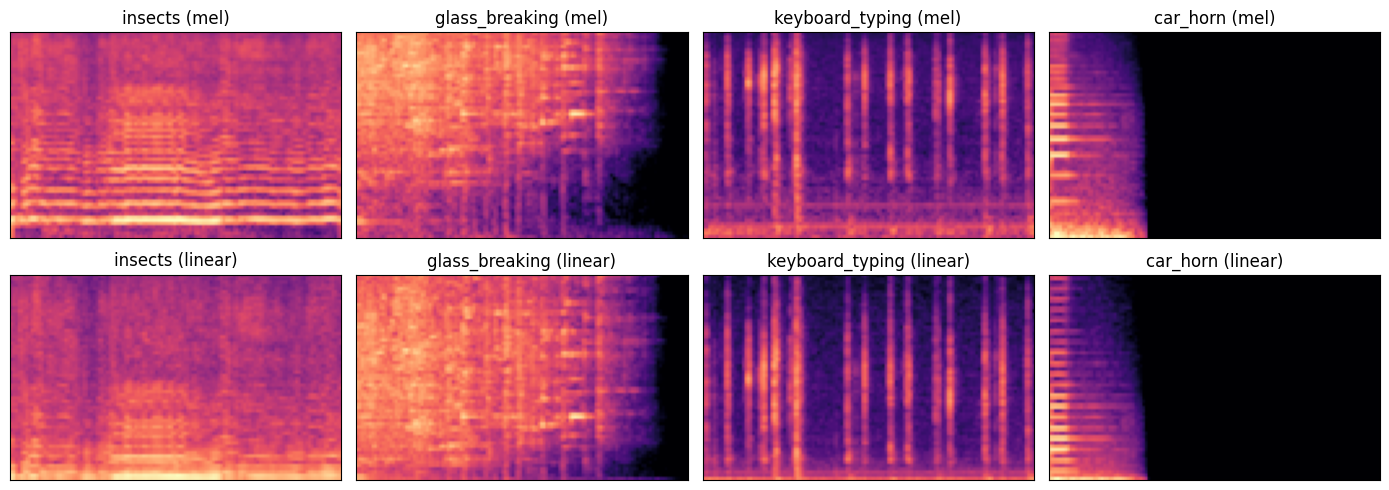

In [ ]:
# The same four clips on both frequency axes: mel (top) and linear (bottom)
fig, axes = plt.subplots(2, 4, figsize=(14, 5))
for col in range(4):
    wave, label = train_set[torch.randint(len(train_set), (1,)).item()]
    for row, (fe, tag) in enumerate([(mel_frontend, "mel"), (frontend, "linear")]):
        axes[row, col].imshow(fe(wave[None])[0, 0].cpu(), origin="lower", aspect="auto", cmap="magma", vmin=-1, vmax=1)
        axes[row, col].set_title(f"{data['class_names'][label]} ({tag})")
        axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
plt.tight_layout(); plt.show()

### How much the linear-to-mel conversion loses

Path C is scored in mel space, so its samples are converted with `C.linear_to_mel`. The
conversion is approximate: below about 1 kHz, mel bands are narrower than the linear
bands, and that detail cannot be recovered. The cell below measures the error on real
held-out audio by comparing a direct mel spectrogram with one obtained through the
linear route. The evaluation notebook passes the real reference through the same
conversion, so Path C is compared like for like.

In [ ]:
ref_wave, ref_labels = C.reference_crops(heldout_split, cfg, k=1)
ref_mel    = torch.cat([mel_frontend(ref_wave[i : i + 64]).cpu() for i in range(0, len(ref_wave), 64)])
ref_linear = torch.cat([frontend(ref_wave[i : i + 64]).cpu() for i in range(0, len(ref_wave), 64)])
ref_via_linear = C.linear_to_mel(ref_linear, frontend, mel_frontend)

err_db = (ref_via_linear - ref_mel).abs() * cfg.db_range / 2
print(f"conversion error on held-out real audio: mean {err_db.mean():.2f} dB, 95th percentile {err_db.flatten()[::97].quantile(0.95):.2f} dB")

conversion error on held-out real audio: mean 2.41 dB, 95th percentile 7.16 dB


## 4. Model

`C.build_unet2d` returns the same network Path A uses: three levels (64 / 128 / 256
channels), two ResNet layers per level, attention at the 16 x 32 bottleneck, scale-shift
conditioning, and a class embedding with a "no label" entry.

| Choice | Reason |
|---|---|
| Identical architecture and parameter count to Path A | The frequency axis is the only variable, so any difference in results is attributable to it. |
| Input stays 64 x 128 | Pooling the 513 STFT bins into 64 linear bands keeps the model's cost and effective capacity the same as Path A's. A full-resolution STFT would be eight times larger. |
| No frequency-position channel | Kept off, as in Path A's baseline. On a linear axis harmonics are evenly spaced, which already suits convolution. |

In [ ]:
def forward_fn(model, x, t, labels):
    return model(x, t, class_labels=labels).sample

unet_c = C.build_unet2d(cfg, dropout=DROPOUT).to(device)
n_params = sum(p.numel() for p in unet_c.parameters())
print(f"Path C params: {n_params:,}")

Path C params: 16,442,433


## 5. Train

Resumes from `RUN_DIR/last.pt` if it exists. For a run you will report, start from an empty
`RUN_DIR` and do not change `total_steps` partway through.

step 100/5000  loss 0.5162
step 200/5000  loss 0.2175
step 300/5000  loss 0.1485
step 400/5000  loss 0.1248
step 500/5000  loss 0.1121
step 600/5000  loss 0.1064
step 700/5000  loss 0.0963
step 800/5000  loss 0.0927
step 900/5000  loss 0.0913
step 1000/5000  loss 0.0924
step 1100/5000  loss 0.0894
step 1200/5000  loss 0.0822
step 1300/5000  loss 0.0836
step 1400/5000  loss 0.0814
step 1500/5000  loss 0.0841
step 1600/5000  loss 0.0837
step 1700/5000  loss 0.0804
step 1800/5000  loss 0.0813
step 1900/5000  loss 0.0807
step 2000/5000  loss 0.0776
step 2100/5000  loss 0.0796
step 2200/5000  loss 0.0752
step 2300/5000  loss 0.0742
step 2400/5000  loss 0.0747
step 2500/5000  loss 0.0776
step 2600/5000  loss 0.0743
step 2700/5000  loss 0.0733
step 2800/5000  loss 0.0734
step 2900/5000  loss 0.0775
step 3000/5000  loss 0.0734
step 3100/5000  loss 0.0768
step 3200/5000  loss 0.0723
step 3300/5000  loss 0.0732
step 3400/5000  loss 0.0719
step 3500/5000  loss 0.0763
step 3600/5000  loss 0.0727
s

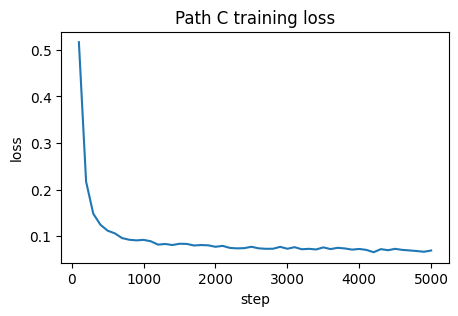

In [ ]:
ema, losses = C.train_diffusion(unet_c, forward_fn, frontend, train_set, cfg, RUN_DIR, device)

plt.figure(figsize=(5, 3))
plt.plot([cfg.log_every * (i + 1) for i in range(len(losses))], losses)
plt.xlabel("step"); plt.ylabel("loss"); plt.title("Path C training loss")
plt.show()

## 6. Generate and save samples

`LINEAR_FILE` holds the samples as the model produced them. `MEL_FILE` holds the same
samples converted to mel, in the same format as the other paths' files.

In [ ]:
gen_labels = C.balanced_labels(cfg, N_PER_CLASS)
generated = C.sample(unet_c, forward_fn, SAMPLE_SHAPE, cfg, device,
                     labels=gen_labels, ema=ema, guidance=GUIDANCE)
gen_mel = C.linear_to_mel(generated, frontend, mel_frontend)

meta = dict(path="C", guidance=GUIDANCE, steps=cfg.inference_steps, n_params=n_params, train_steps=cfg.total_steps)
C.save_samples(LINEAR_FILE, generated, gen_labels, cfg, representation="linear", **meta)
C.save_samples(MEL_FILE, gen_mel, gen_labels, cfg, representation="mel_via_linear", **meta)
print("saved", tuple(generated.shape), "and", tuple(gen_mel.shape))
print(f"value range: [{generated.min():.3f}, {generated.max():.3f}]")

saved (800, 1, 64, 128) and (800, 1, 64, 128)
value range: [-1.000, 1.000]


## 7. Visual check

Held-out real linear spectrograms (top) against generated ones of the same class (bottom).
This is a sanity check only.

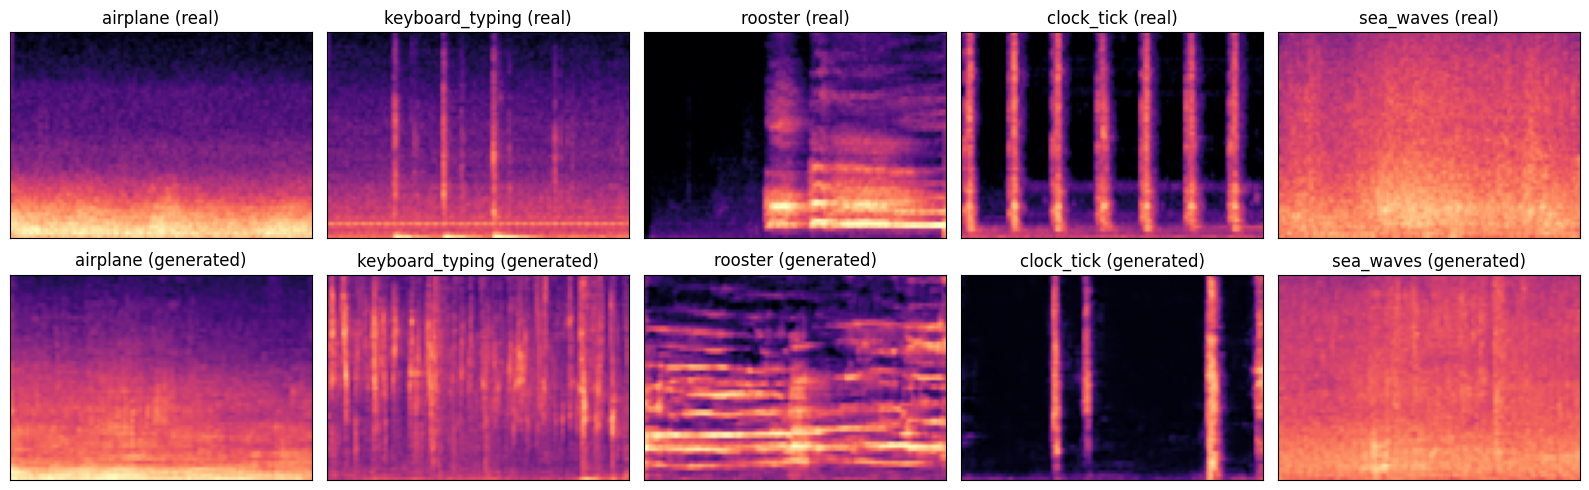

In [ ]:
show = torch.randperm(cfg.num_classes)[:5].tolist()

fig, axes = plt.subplots(2, 5, figsize=(16, 5))
for col, c in enumerate(show):
    real = ref_linear[ref_labels == c][0, 0]
    fake = generated[gen_labels == c][0, 0]
    for row, (img, tag) in enumerate([(real, "real"), (fake, "generated")]):
        axes[row, col].imshow(img, origin="lower", aspect="auto", cmap="magma", vmin=-1, vmax=1)
        axes[row, col].set_title(f"{data['class_names'][c]} ({tag})")
        axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
plt.tight_layout(); plt.show()